# Activité Pratique N°4 — Architecture Transformer
**Module :** IA Générative Multi-Modale — Pr. Mohamed YOUSSFI
**Étudiante :** Salma Chair — 5IIR / IA & Data, EMSI

**Travail réalisé**
1. Génération d'une série temporelle y = sin(x)
2. RNN : prédire la valeur suivante d'une séquence de 10 éléments
3. LSTM : même tâche
4. Transformer (encodeur + encodage positionnel) : même tâche
5. Comparaison RNN / LSTM / Transformer (+ prévision autorégressive)
6. Modèle de type **GPT** (décodeur, causal) : prédire la suite d'un texte
7. Modèle de type **BERT** (encodeur, bidirectionnel) : prédire un mot masqué

**Environnement (UV, macOS)**
```bash
uv init --python=3.11 && uv venv && source .venv/bin/activate
uv add ipykernel torch matplotlib numpy transformers
```

In [1]:
import math, time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42); np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch :", torch.__version__, "| appareil :", device)

PyTorch : 2.11.0 | appareil : cpu


---
## 1. Série temporelle y = sin(x)
On crée des **fenêtres glissantes** : 10 valeurs consécutives → la 11ᵉ valeur à prédire.
Découpage **chronologique** 80 % / 20 % (pas de mélange avant le découpage : on teste sur le « futur »).

X : torch.Size([1990, 10, 1]) | y : torch.Size([1990, 1])
Train : torch.Size([1592, 10, 1]) | Test : torch.Size([398, 10, 1])


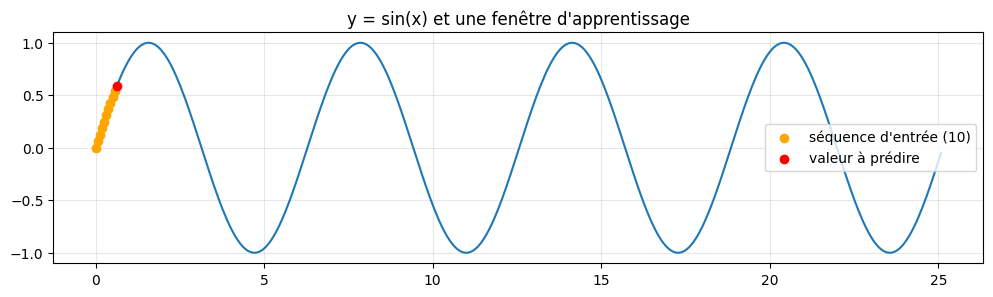

In [2]:
TAILLE_SEQ = 10

x = torch.linspace(0, 40 * math.pi, 2000)        # 20 périodes
serie = torch.sin(x)

def creer_sequences(serie, taille=TAILLE_SEQ):
    X, y = [], []
    for i in range(len(serie) - taille):
        X.append(serie[i:i + taille])
        y.append(serie[i + taille])
    X = torch.stack(X).unsqueeze(-1)    # (N, 10, 1) : batch, temps, caractéristiques
    y = torch.stack(y).unsqueeze(-1)    # (N, 1)
    return X, y

X, y = creer_sequences(serie)
limite = int(0.8 * len(X))
X_train, y_train = X[:limite].to(device), y[:limite].to(device)
X_test, y_test = X[limite:].to(device), y[limite:].to(device)
print("X :", X.shape, "| y :", y.shape)
print("Train :", X_train.shape, "| Test :", X_test.shape)

plt.figure(figsize=(12, 3))
plt.plot(x[:400], serie[:400])
plt.scatter(x[:TAILLE_SEQ], serie[:TAILLE_SEQ], color="orange", zorder=3, label="séquence d'entrée (10)")
plt.scatter(x[TAILLE_SEQ], serie[TAILLE_SEQ], color="red", zorder=3, label="valeur à prédire")
plt.title("y = sin(x) et une fenêtre d'apprentissage"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Fonctions communes** d'entraînement (mini-lots) et d'évaluation, réutilisées par les 3 modèles.

In [3]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

def entrainer(modele, epochs=30, lr=1e-3, nom=""):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(modele.parameters(), lr=lr)
    historique, t0 = [], time.time()
    for epoch in range(epochs):
        modele.train()
        total = 0.0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = criterion(modele(xb), yb)
            loss.backward()
            optimizer.step()
            total += loss.item() * xb.size(0)
        historique.append(total / len(train_loader.dataset))
        if (epoch + 1) % 10 == 0:
            print(f"[{nom}] Époque {epoch+1}/{epochs} | MSE train : {historique[-1]:.6f}")
    print(f"[{nom}] durée : {time.time() - t0:.1f} s | paramètres : {sum(p.numel() for p in modele.parameters())}")
    return historique

@torch.no_grad()
def tester(modele, nom=""):
    modele.eval()
    pred = modele(X_test)
    mse = nn.functional.mse_loss(pred, y_test).item()
    mae = (pred - y_test).abs().mean().item()
    print(f"[{nom}] Test -> MSE : {mse:.6f} | MAE : {mae:.4f}")
    return pred.cpu(), mse, mae

def tracer(pred, historique, nom):
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), gridspec_kw={"width_ratios": [1, 2.5]})
    axes[0].plot(historique); axes[0].set_yscale("log"); axes[0].set_title(f"{nom} — perte (log)"); axes[0].set_xlabel("Époque")
    axes[1].plot(y_test.cpu()[:200], label="réel", lw=2)
    axes[1].plot(pred[:200], "--", label="prédit")
    axes[1].set_title(f"{nom} — prédiction de la valeur suivante (200 premiers points du test)"); axes[1].legend()
    for a in axes: a.grid(alpha=.3)
    plt.tight_layout(); plt.show()

resultats = {}

---
## 2. RNN
À chaque instant t : **h_t = tanh(W_x·x_t + W_h·h_{t−1} + b)**. La même cellule est réutilisée à chaque pas de temps ; le dernier état caché h₁₀ résume la séquence et une couche linéaire prédit la valeur suivante.
Limite : gradients qui s'évanouissent / explosent sur les longues séquences.

[RNN] Époque 10/30 | MSE train : 0.000881
[RNN] Époque 20/30 | MSE train : 0.000523
[RNN] Époque 30/30 | MSE train : 0.000366
[RNN] durée : 0.6 s | paramètres : 1153
[RNN] Test -> MSE : 0.000341 | MAE : 0.0165


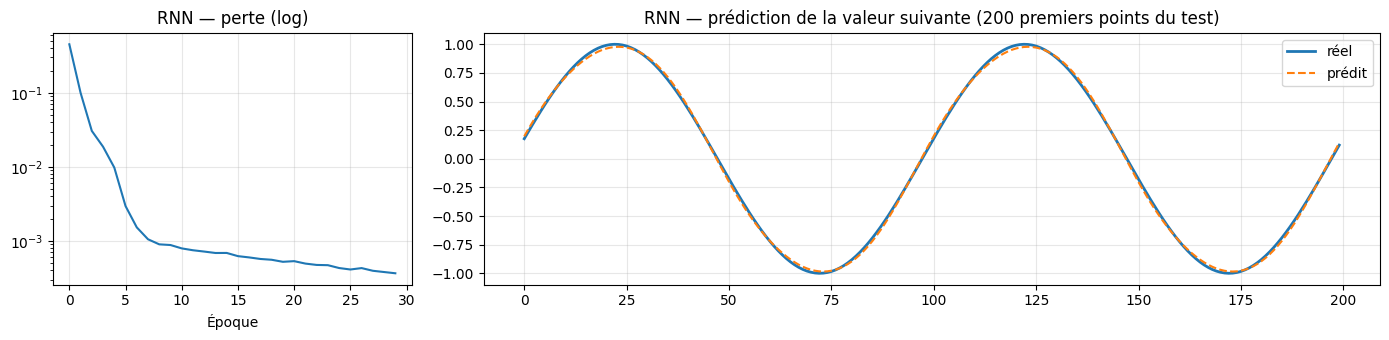

In [4]:
class ModeleRNN(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.sortie = nn.Linear(hidden_size, 1)
    def forward(self, x):                 # x : (batch, 10, 1)
        out, h_n = self.rnn(x)            # out : (batch, 10, hidden)
        return self.sortie(out[:, -1])    # dernier pas de temps -> (batch, 1)

rnn = ModeleRNN().to(device)
hist_rnn = entrainer(rnn, nom="RNN")
pred_rnn, mse, mae = tester(rnn, "RNN")
resultats["RNN"] = (rnn, mse, mae)
tracer(pred_rnn, hist_rnn, "RNN")

---
## 3. LSTM
Le LSTM ajoute une **mémoire de cellule c_t** contrôlée par 3 portes :
- **porte d'oubli** f_t : ce qu'on efface de c_{t−1} ;
- **porte d'entrée** i_t : ce qu'on ajoute ;
- **porte de sortie** o_t : ce qu'on expose dans h_t.

c_t = f_t ⊙ c_{t−1} + i_t ⊙ g_t et h_t = o_t ⊙ tanh(c_t) → le gradient circule mieux dans le temps.

[LSTM] Époque 10/30 | MSE train : 0.001132
[LSTM] Époque 20/30 | MSE train : 0.000079
[LSTM] Époque 30/30 | MSE train : 0.000012
[LSTM] durée : 1.2 s | paramètres : 4513
[LSTM] Test -> MSE : 0.000020 | MAE : 0.0037


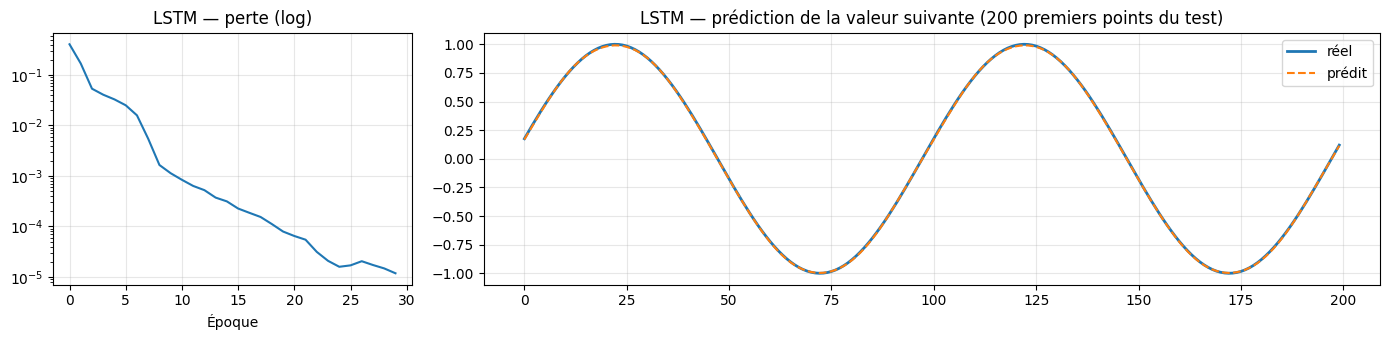

In [5]:
class ModeleLSTM(nn.Module):
    def __init__(self, hidden_size=32, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
        self.sortie = nn.Linear(hidden_size, 1)
    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        return self.sortie(out[:, -1])

lstm = ModeleLSTM().to(device)
hist_lstm = entrainer(lstm, nom="LSTM")
pred_lstm, mse, mae = tester(lstm, "LSTM")
resultats["LSTM"] = (lstm, mse, mae)
tracer(pred_lstm, hist_lstm, "LSTM")

---
## 4. Transformer
Plus de récurrence : toutes les positions sont traitées **en parallèle** grâce à la **self-attention** :

**Attention(Q, K, V) = softmax(Q·Kᵀ / √d_k) · V**

- Chaque valeur (scalaire) est projetée en un vecteur de dimension `d_model` (embedding linéaire).
- Comme l'attention ignore l'ordre, on ajoute un **encodage positionnel** sinusoïdal : PE(pos, 2i) = sin(pos/10000^{2i/d}), PE(pos, 2i+1) = cos(...).
- `nn.TransformerEncoder` : *multi-head attention* + *feed-forward* + connexions résiduelles + LayerNorm.
- La représentation de la **dernière position** sert à prédire la valeur suivante.

[Transformer] Époque 10/30 | MSE train : 0.000114
[Transformer] Époque 20/30 | MSE train : 0.000020
[Transformer] Époque 30/30 | MSE train : 0.000004
[Transformer] durée : 2.0 s | paramètres : 17185
[Transformer] Test -> MSE : 0.000004 | MAE : 0.0015


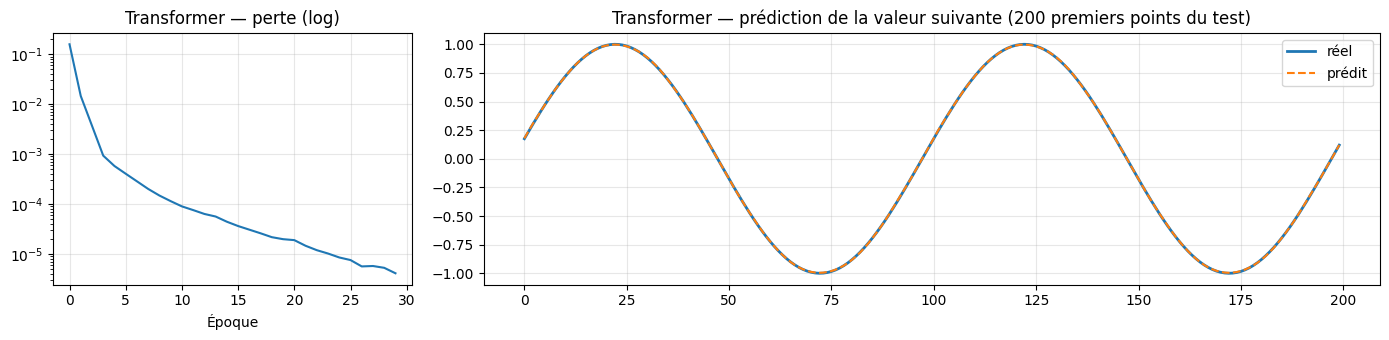

In [6]:
class EncodagePositionnel(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))     # (1, max_len, d_model)
    def forward(self, x):
        return x + self.pe[:, :x.size(1)]

class ModeleTransformer(nn.Module):
    def __init__(self, d_model=32, nhead=4, num_layers=2, dim_ff=64, dropout=0.0):
        super().__init__()
        self.embedding = nn.Linear(1, d_model)
        self.pos = EncodagePositionnel(d_model)
        couche = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=dim_ff,
                                            dropout=dropout, batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, num_layers=num_layers)
        self.sortie = nn.Linear(d_model, 1)
    def forward(self, x):                  # (batch, 10, 1)
        h = self.pos(self.embedding(x))    # (batch, 10, d_model)
        h = self.encodeur(h)               # self-attention entre les 10 positions
        return self.sortie(h[:, -1])       # (batch, 1)

transformer = ModeleTransformer().to(device)
hist_tr = entrainer(transformer, nom="Transformer")
pred_tr, mse, mae = tester(transformer, "Transformer")
resultats["Transformer"] = (transformer, mse, mae)
tracer(pred_tr, hist_tr, "Transformer")

**Visualiser l'attention** : quelles positions de la séquence la dernière position regarde-t-elle ? (1ʳᵉ couche, moyenne des têtes)

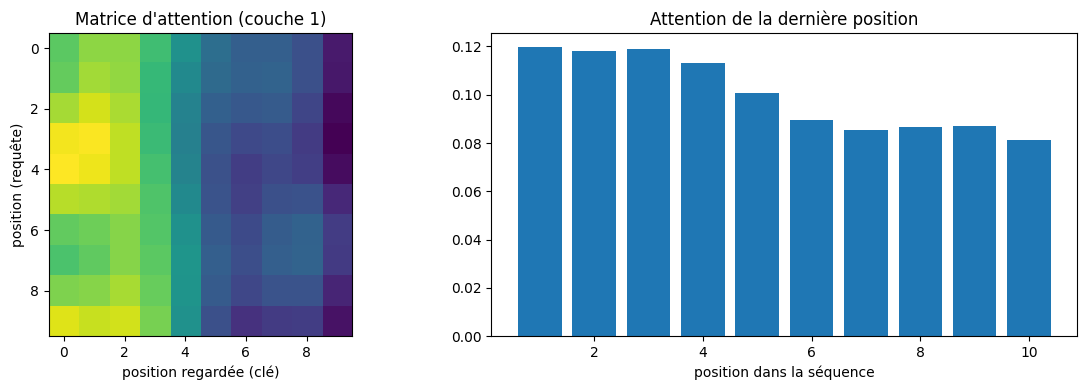

In [7]:
@torch.no_grad()
def poids_attention(modele, seq):
    modele.eval()
    h = modele.pos(modele.embedding(seq))
    couche = modele.encodeur.layers[0]
    _, w = couche.self_attn(h, h, h, need_weights=True, average_attn_weights=True)
    return w[0].cpu()                     # (10, 10)

w = poids_attention(transformer, X_test[:1])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(w, cmap="viridis"); axes[0].set_xlabel("position regardée (clé)"); axes[0].set_ylabel("position (requête)")
axes[0].set_title("Matrice d'attention (couche 1)")
axes[1].bar(range(1, 11), w[-1]); axes[1].set_xlabel("position dans la séquence"); axes[1].set_title("Attention de la dernière position")
plt.tight_layout(); plt.show()

---
## 5. Comparaison des trois modèles
### 5.1 Prédiction à un pas (test)

Modèle          MSE test  MAE test  Paramètres
RNN             0.000341    0.0165        1153
LSTM            0.000020    0.0037        4513
Transformer     0.000004    0.0015       17185


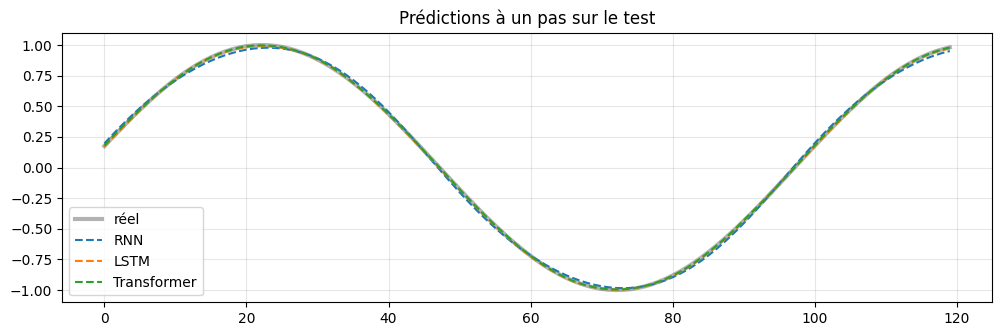

In [8]:
print(f"{'Modèle':<12}{'MSE test':>12}{'MAE test':>10}{'Paramètres':>12}")
for nom, (m, mse, mae) in resultats.items():
    print(f"{nom:<12}{mse:>12.6f}{mae:>10.4f}{sum(p.numel() for p in m.parameters()):>12}")

plt.figure(figsize=(12, 3.5))
plt.plot(y_test.cpu()[:120], "k", lw=3, alpha=.3, label="réel")
for nom, p in [("RNN", pred_rnn), ("LSTM", pred_lstm), ("Transformer", pred_tr)]:
    plt.plot(p[:120], "--", label=nom)
plt.legend(); plt.grid(alpha=.3); plt.title("Prédictions à un pas sur le test"); plt.show()

### 5.2 Prévision autorégressive (bonus)
On ne donne que les 10 premières valeurs, puis le modèle **réinjecte ses propres prédictions** pour prévoir 200 pas. Les erreurs s'accumulent : c'est un test plus exigeant (même principe que la génération de texte par GPT, token par token).

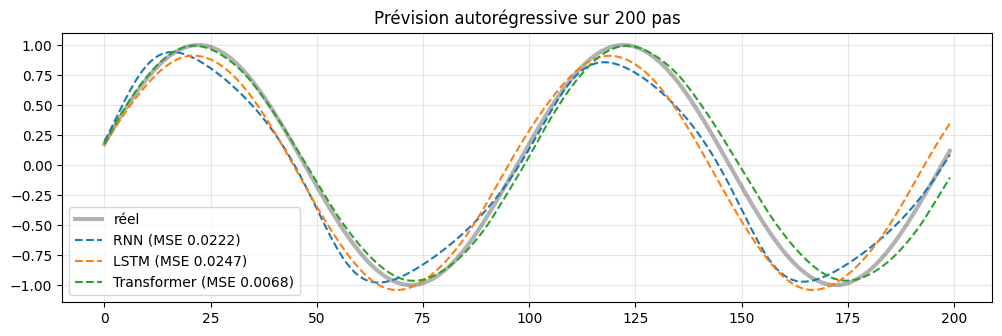

In [9]:
@torch.no_grad()
def prevoir(modele, sequence_initiale, n_pas=200):
    modele.eval()
    fenetre = sequence_initiale.clone().view(1, TAILLE_SEQ, 1).to(device)
    sorties = []
    for _ in range(n_pas):
        suivant = modele(fenetre)                                  # (1, 1)
        sorties.append(suivant.item())
        fenetre = torch.cat([fenetre[:, 1:], suivant.view(1, 1, 1)], dim=1)
    return np.array(sorties)

depart = X_test[0, :, 0]
reel = y_test[:200, 0].cpu().numpy()
plt.figure(figsize=(12, 3.5))
plt.plot(reel, "k", lw=3, alpha=.3, label="réel")
for nom, (m, _, _) in resultats.items():
    p = prevoir(m, depart)
    plt.plot(p, "--", label=f"{nom} (MSE {np.mean((p - reel) ** 2):.4f})")
plt.legend(); plt.grid(alpha=.3); plt.title("Prévision autorégressive sur 200 pas"); plt.show()

### 5.3 Analyse (résultats obtenus)
| Modèle | MSE test (1 pas) | MAE test | Paramètres | MSE autorégressive (200 pas) |
|---|---|---|---|---|
| RNN | 0.000341 | 0.0165 | 1 153 | 0.0222 |
| LSTM | 0.000020 | 0.0037 | 4 513 | 0.0247 |
| Transformer | **0.000004** | **0.0015** | 17 185 | **0.0068** |

- Les trois modèles prédisent très bien la valeur suivante de sin(x) (MAE < 0,02 sur une amplitude de 2).
- Le **RNN** est le plus simple et le plus rapide, mais le moins précis : toute l'information passe par un seul état caché tanh.
- Le **LSTM** divise l'erreur par ~17 grâce à sa mémoire c_t et à ses portes, avec ~4× plus de paramètres.
- Le **Transformer** obtient la plus faible erreur, à un pas comme en prévision autorégressive (où les erreurs s'accumulent et les modèles récurrents se déphasent). Chaque position voit directement les 10 valeurs via l'attention (calcul **parallèle**), l'ordre étant donné par l'**encodage positionnel**. Contrepartie : plus de paramètres et un entraînement plus lent sur CPU.
- Sur un signal aussi simple, l'écart reste modeste ; l'avantage du Transformer devient décisif sur de longues séquences et de gros volumes (texte), d'où son usage dans GPT et BERT.

---
## 6. Modèle de type GPT — prédire la suite d'un texte
**GPT = pile de blocs *décodeurs* du Transformer** avec **attention masquée (causale)** : chaque token ne voit que les tokens précédents. Il est entraîné à **prédire le token suivant** ; la génération est **autorégressive** (on ajoute le token prédit et on recommence), exactement comme la prévision de la section 5.2.

On utilise **GPT-2** pré-entraîné (Hugging Face `transformers`). GPT-2 a été entraîné en anglais, donc les exemples sont en anglais.

In [10]:
from transformers import AutoTokenizer, AutoModelForCausalLM

gpt_tok = AutoTokenizer.from_pretrained("gpt2")
gpt = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()
print("Paramètres GPT-2 :", f"{sum(p.numel() for p in gpt.parameters()) / 1e6:.0f} M")

prompt = "Artificial intelligence will change the way students"
ids = gpt_tok(prompt, return_tensors="pt").to(device)
print("Tokens :", gpt_tok.convert_ids_to_tokens(ids["input_ids"][0]))

/Users/mac/Library/Python/3.13/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 19:46:29.594000 81389 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 11720.80it/s]

Paramètres GPT-2 : 124 M
Tokens : ['Art', 'ificial', 'Ġintelligence', 'Ġwill', 'Ġchange', 'Ġthe', 'Ġway', 'Ġstudents']


In [11]:
import sys

print("Python utilisé par Jupyter :", sys.executable)

!{sys.executable} -m pip install -U transformers

Python utilisé par Jupyter : /usr/local/bin/python3
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


**6.1 Un pas : distribution de probabilité du token suivant**

In [12]:
with torch.no_grad():
    logits = gpt(**ids).logits                # (1, nb_tokens, 50257)
probas = torch.softmax(logits[0, -1], dim=-1)
top = torch.topk(probas, 10)
print(f"Prompt : '{prompt}' → token suivant :")
for p, i in zip(top.values, top.indices):
    print(f"  {gpt_tok.decode(i)!r:<16} {p.item():.2%}")

Prompt : 'Artificial intelligence will change the way students' → token suivant :
  ' learn'         19.52%
  ' think'         14.60%
  ' are'           7.32%
  ' interact'      5.93%
  ' and'           3.27%
  ' work'          3.00%
  ' see'           1.96%
  ' view'          1.90%
  ' study'         1.64%
  ' do'            1.60%


**6.2 Génération de la suite** — décodage glouton (greedy) vs échantillonnage (température, top-k, top-p)

In [13]:
def generer(prompt, max_new_tokens=40, sampling=False, **kwargs):
    entree = gpt_tok(prompt, return_tensors="pt").to(device)
    torch.manual_seed(0)
    with torch.no_grad():
        sortie = gpt.generate(**entree, max_new_tokens=max_new_tokens, do_sample=sampling,
                              pad_token_id=gpt_tok.eos_token_id, **kwargs)
    return gpt_tok.decode(sortie[0], skip_special_tokens=True)

print("GREEDY :\n", generer(prompt), "\n")
print("GREEDY + no_repeat_ngram_size=3 :\n", generer(prompt, no_repeat_ngram_size=3), "\n")
print("SAMPLING (T=0.8, top_k=50, top_p=0.95) :\n",
      generer(prompt, sampling=True, temperature=0.8, top_k=50, top_p=0.95))

GREEDY :
 Artificial intelligence will change the way students learn, and the way they learn.

The future of education is not a question of whether we will have a better education system, but of how we will teach it.

The future 

GREEDY + no_repeat_ngram_size=3 :
 Artificial intelligence will change the way students learn, and the way they learn.

The future of education is not a question of whether we will have a better education system, but of how we will teach it.
. 

SAMPLING (T=0.8, top_k=50, top_p=0.95) :
 Artificial intelligence will change the way students understand science and society," said John Stupak, an associate professor at the University of California, Irvine.

"We can't just change the way it's taught and applied. We need


In [14]:
for p in ["The Transformer architecture is based on",
          "Once upon a time, in Casablanca,",
          "def fibonacci(n):"]:
    print("▶", generer(p, max_new_tokens=35, sampling=True, temperature=0.7, top_p=0.9), "\n")

▶ The Transformer architecture is based on a new series of modular reactors that is designed to produce 10-50 MW of power and 30-100 MW of CO2. The company has already completed the first phase of 

▶ Once upon a time, in Casablanca, a man named Joseph B. de la Cruz became president.

In the days leading up to the election, de la Cruz was the main figure in the Republican establishment. 

▶ def fibonacci(n): #f=f(n)

Example:

#f=f(n) #f=f(n)

The problem with this is that 



**6.3 La génération pas à pas « à la main »** (ce que fait `generate` en interne) : on prend le token le plus probable, on l'ajoute, on recommence.

In [15]:
ids_courants = gpt_tok("The capital of Morocco is", return_tensors="pt")["input_ids"].to(device)
for etape in range(8):
    with torch.no_grad():
        prochain = gpt(ids_courants).logits[0, -1].argmax()
    ids_courants = torch.cat([ids_courants, prochain.view(1, 1)], dim=1)
    print(f"étape {etape+1}: + {gpt_tok.decode(prochain)!r:<12} → {gpt_tok.decode(ids_courants[0])}")

étape 1: + ' the'       → The capital of Morocco is the
étape 2: + ' capital'   → The capital of Morocco is the capital
étape 3: + ' of'        → The capital of Morocco is the capital of
étape 4: + ' the'       → The capital of Morocco is the capital of the
étape 5: + ' Islamic'   → The capital of Morocco is the capital of the Islamic
étape 6: + ' State'     → The capital of Morocco is the capital of the Islamic State
étape 7: + ' group'     → The capital of Morocco is the capital of the Islamic State group
étape 8: + ','          → The capital of Morocco is the capital of the Islamic State group,


*Observations :* le décodage glouton est déterministe mais tombe souvent dans des **répétitions** ; l'échantillonnage (température, top-k, top-p) produit des textes plus variés mais parfois moins cohérents. GPT-2 (124 M paramètres) génère un texte fluide mais **pas forcément vrai** : il prédit ce qui est probable, pas ce qui est exact.

---
## 7. Modèle de type BERT — prédire un mot masqué
**BERT = pile de blocs *encodeurs*** : l'attention est **bidirectionnelle**, chaque token voit le contexte à gauche **et** à droite.
Il est pré-entraîné par **Masked Language Modeling (MLM)** : on remplace ~15 % des tokens par `[MASK]` et le modèle doit les retrouver. Il ne génère pas de texte libre, mais il **comprend** le contexte (classification, NER, recherche sémantique…).

In [16]:
from transformers import AutoModelForMaskedLM

bert_tok = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModelForMaskedLM.from_pretrained("bert-base-uncased").to(device).eval()
print("Paramètres BERT-base :", f"{sum(p.numel() for p in bert.parameters()) / 1e6:.0f} M | masque :", bert_tok.mask_token)

def predire_masque(phrase, tok=bert_tok, modele=bert, k=5):
    entree = tok(phrase, return_tensors="pt").to(device)
    pos = (entree["input_ids"][0] == tok.mask_token_id).nonzero().flatten()
    with torch.no_grad():
        logits = modele(**entree).logits[0]
    print(f"\n{phrase}")
    for p_ in pos:
        probas = torch.softmax(logits[p_], dim=-1)
        top = torch.topk(probas, k)
        print("   → " + " | ".join(f"{tok.decode(i).strip()} ({v.item():.1%})" for v, i in zip(top.values, top.indices)))

predire_masque("The capital of France is [MASK].")
predire_masque("The Transformer model relies entirely on [MASK] mechanisms.")
predire_masque("She went to the [MASK] to buy some bread.")
predire_masque("The doctor prescribed [MASK] for the [MASK].")

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 9297.97it/s]
[transformers] BertForMaskedLM LOAD REPORT from: bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.weight | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Paramètres BERT-base : 110 M | masque : [MASK]

The capital of France is [MASK].
   → paris (41.7%) | lille (7.1%) | lyon (6.3%) | marseille (4.4%) | tours (3.0%)

The Transformer model relies entirely on [MASK] mechanisms.
   → two (12.1%) | mechanical (9.7%) | simple (3.9%) | several (3.7%) | these (3.0%)

She went to the [MASK] to buy some bread.
   → market (71.9%) | bakery (6.1%) | store (5.8%) | kitchen (5.6%) | shop (1.7%)

The doctor prescribed [MASK] for the [MASK].
   → antibiotics (17.9%) | medication (10.1%) | him (4.5%) | drugs (3.7%) | blood (3.5%)
   → patient (9.2%) | baby (5.5%) | child (3.5%) | boy (3.3%) | wound (2.3%)


**7.1 Le contexte droit compte** (bidirectionnalité) : même début de phrase, fin différente → prédiction différente.

In [17]:
predire_masque("I went to the [MASK] to swim.")
predire_masque("I went to the [MASK] to watch a movie.")
predire_masque("I went to the [MASK] to borrow a book.")


I went to the [MASK] to swim.
   → lake (27.7%) | pool (24.9%) | river (15.0%) | beach (5.6%) | ocean (4.8%)

I went to the [MASK] to watch a movie.
   → bathroom (13.0%) | theater (13.0%) | cinema (7.8%) | couch (6.5%) | library (4.8%)

I went to the [MASK] to borrow a book.
   → library (61.9%) | bookstore (22.1%) | store (4.1%) | bathroom (2.7%) | office (0.7%)


**7.2 Avec le pipeline `fill-mask`**, et un BERT **français** (CamemBERT, masque `<mask>`)

In [18]:
from transformers import pipeline

fill_fr = pipeline("fill-mask", model="camembert-base", device=0 if device.type == "cuda" else -1)
for phrase in ["Casablanca est la plus grande <mask> du Maroc.",
               "Le Transformer repose sur le mécanisme d'<mask>."]:
    print("\n" + phrase)
    for r in fill_fr(phrase, top_k=5):
        print(f"   → {r['token_str']:<12} {r['score']:.1%}")

Loading weights: 100%|██████████| 202/202 [00:00<00:00, 8174.85it/s]
[transformers] CamembertForMaskedLM LOAD REPORT from: camembert-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Casablanca est la plus grande <mask> du Maroc.
   → ville        90.1%
   → métropole    5.2%
   → capitale     2.3%
   → université   0.5%
   → commune      0.3%

Le Transformer repose sur le mécanisme d'<mask>.
   → ouverture    9.4%
   → entraînement 7.7%
   → interrupteur 4.3%
   → action       3.5%
   → assemblage   2.4%


---
## Conclusion
| Modèle | Principe | Traitement de la séquence | Tâche réalisée |
|---|---|---|---|
| RNN | état caché h_t récurrent | séquentiel | valeur suivante de sin(x) |
| LSTM | RNN + mémoire c_t et 3 portes | séquentiel | valeur suivante de sin(x) |
| Transformer | self-attention + encodage positionnel | **parallèle** | valeur suivante de sin(x) |
| GPT | **décodeur** Transformer, attention **causale** | gauche → droite, autorégressif | générer la suite d'un texte |
| BERT | **encodeur** Transformer, attention **bidirectionnelle** | contexte complet | retrouver un mot masqué |

- Les trois modèles séquentiels atteignent une très faible erreur sur sin(x) ; le Transformer remplace la récurrence par l'attention, ce qui permet le parallélisme et les dépendances longues.
- **GPT** et **BERT** réutilisent les deux moitiés de l'architecture *Attention Is All You Need* : GPT le décodeur (génération), BERT l'encodeur (compréhension).